# Arizona Air Challenge: Exploratory Data Analysis

This notebook performs exploratory data analysis (EDA) on the training dataset.

The goal is to understand the data, identify missing values, explore high-ozone patterns, and evaluate potential relationships between predictors before building models.

**Target variable:** `high_ozone`
- 0 = Low ozone
- 1 = High ozone

In [6]:
# Import required libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

# Display more columns in tables
pd.set_option("display.max_columns", 50)

# Load training data
DATA_PATH = "/workspaces/Final-Project-Arizona-Air-Challenge/data/train.csv"

df = pd.read_csv(DATA_PATH)

# Display the first few rows
display(df.head())

,row_id,site_code,year_index,month,season,region,county_name,temperature_mean,temperature_max,temperature_missing,wind_speed_mean,wind_speed_max,wind_speed_missing,relative_humidity_mean,relative_humidity_max,relative_humidity_missing,high_ozone
0,row_562cad979cdb5bba,site_4acff404,0,11,fall,Central,Maricopa,69.000000,88.0,0,1.045833,2.7,0,39.958333,59.0,0,0
1,row_3422e20e75e459f5,site_5f39aea5,0,8,summer,Central,Maricopa,86.625000,98.0,0,3.691667,7.8,0,56.958333,71.0,0,0
2,row_cac8ceeb267d3fc4,site_3b4fabeb,1,7,summer,Central,Maricopa,95.958333,107.0,0,1.725000,4.0,0,20.291667,26.0,0,0
3,row_554b89fd0d1e0990,site_64f8ec06,0,10,fall,Central,Maricopa,NaN,NaN,1,2.466667,5.7,0,NaN,NaN,1,0
4,row_4f5e96fba2cd70f3,site_c715259d,2,3,spring,Central,Pinal,NaN,NaN,1,1.295833,2.5,0,NaN,NaN,1,0


## 1. Data Structure

In [8]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names and data types
print("\nColumn information:")
df.info()

Dataset shape: (46737, 17)
Number of rows: 46737
Number of columns: 17

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 46737 entries, 0 to 46736
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   row_id                     46737 non-null  str    
 1   site_code                  46737 non-null  str    
 2   year_index                 46737 non-null  int64  
 3   month                      46737 non-null  int64  
 4   season                     46737 non-null  str    
 5   region                     46737 non-null  str    
 6   county_name                46737 non-null  str    
 7   temperature_mean           34317 non-null  float64
 8   temperature_max            34317 non-null  float64
 9   temperature_missing        46737 non-null  int64  
 10  wind_speed_mean            35927 non-null  float64
 11  wind_speed_max             35927 non-null  float64
 12  wind_speed_missing   

In [ ]:
# Summarize each column
data_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing Percent": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

display(data_summary)

,Data Type,Missing Values,Missing Percent,Unique Values
row_id,str,0,0.00,46737
site_code,str,0,0.00,46
year_index,int64,0,0.00,3
month,int64,0,0.00,12
season,str,0,0.00,4
region,str,0,0.00,5
county_name,str,0,0.00,10
temperature_mean,float64,12420,26.57,1972
temperature_max,float64,12420,26.57,97
temperature_missing,int64,0,0.00,2


## 2. Missingness

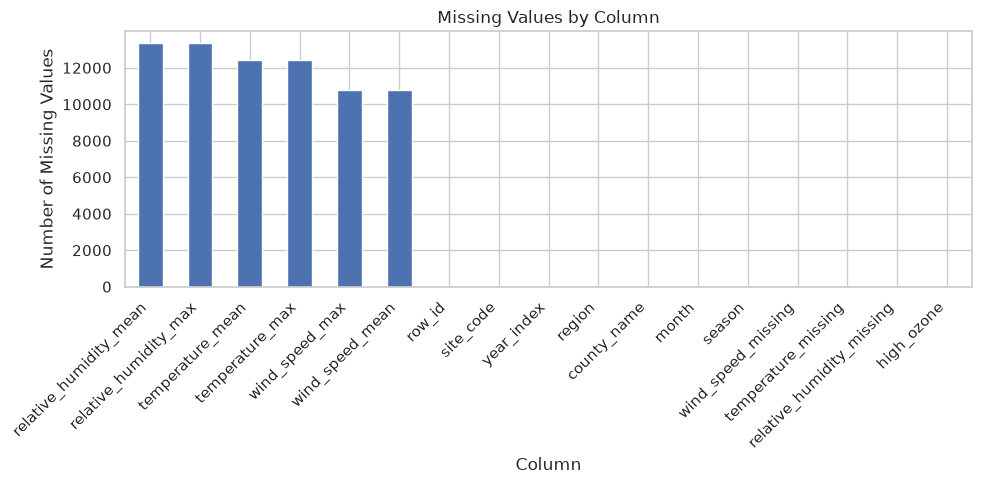

In [12]:
# Calculate missing values by column
missing = df.isnull().sum().sort_values(ascending=False)

# Plot missing values
plt.figure(figsize=(10, 5))

missing.plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

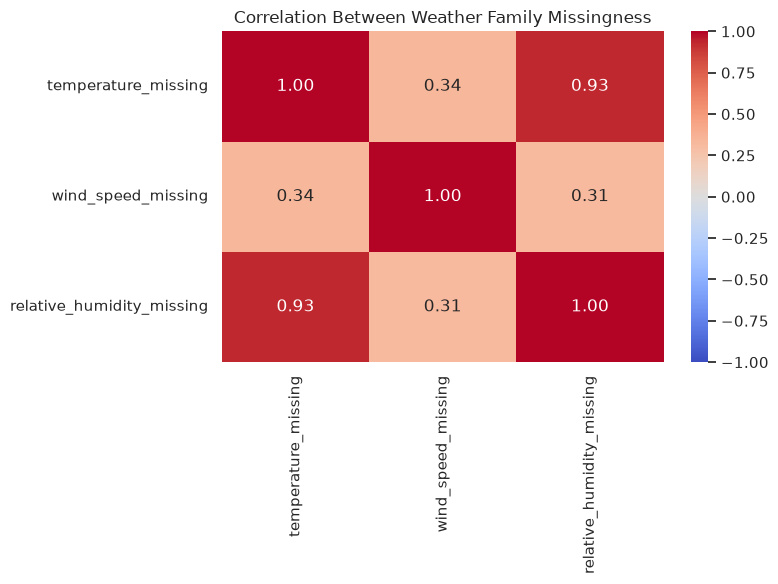

In [20]:
# Select the weather missingness indicator columns
missing_columns = [
    "temperature_missing",
    "wind_speed_missing",
    "relative_humidity_missing"
]

# Calculate correlations between missingness indicators
missing_correlations = df[missing_columns].corr()

# Display the correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    missing_correlations,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Weather Family Missingness")
plt.tight_layout()
plt.show()

## 3. Class Distribution

In [21]:
# Count each target class
class_counts = df["high_ozone"].value_counts().sort_index()

print("Class counts:")
display(class_counts)

# Calculate class percentages
class_percentages = df["high_ozone"].value_counts(normalize=True) * 100

print("\nClass percentages:")
display(class_percentages)

# Calculate overall high-ozone prevalence
base_rate = df["high_ozone"].mean()

print(f"\nOverall high-ozone prevalence: {base_rate:.2%}")

Class counts:


high_ozone
0    45335
1     1402
Name: count, dtype: int64


Class percentages:


high_ozone
0    97.000235
1     2.999765
Name: proportion, dtype: float64


Overall high-ozone prevalence: 3.00%



High-Ozone Prevalence by month:


month
1     1.53
2     0.00
3     0.80
4     1.50
5     3.78
6     7.16
7     9.66
8     7.50
9     1.82
10    0.75
11    0.00
12    0.50
Name: high_ozone, dtype: float64

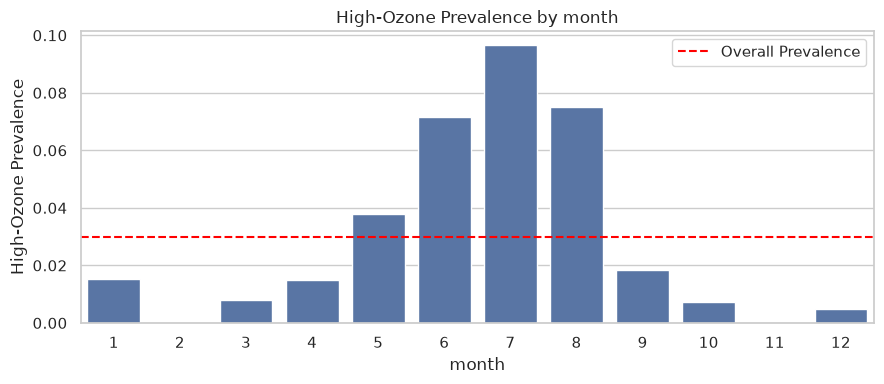


High-Ozone Prevalence by season:


season
fall      0.87
spring    2.05
summer    8.11
winter    0.70
Name: high_ozone, dtype: float64

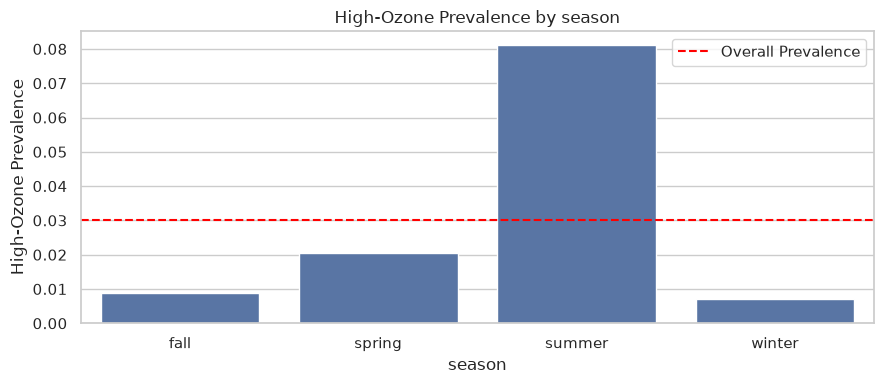


High-Ozone Prevalence by region:


region
Central     4.45
Eastern     2.99
Northern    0.07
Southern    0.34
Western     0.47
Name: high_ozone, dtype: float64

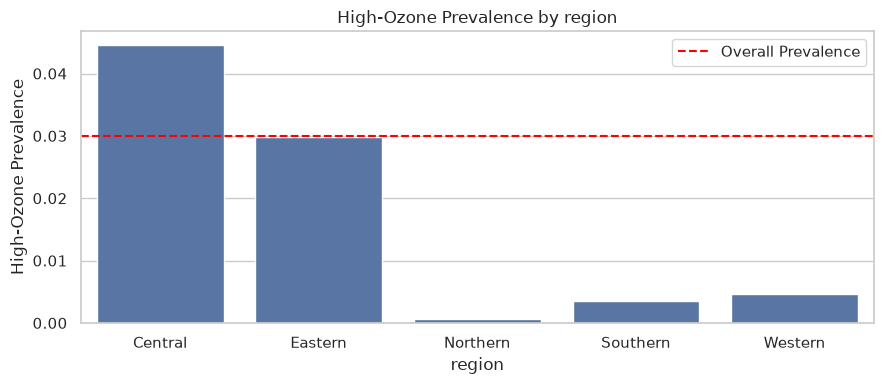

In [23]:
# Create a reusable function to calculate and plot ozone prevalence
def plot_ozone_prevalence(column):

    # Calculate average high-ozone rate by group
    rates = df.groupby(column)["high_ozone"].mean()

    # Display results
    print(f"\nHigh-Ozone Prevalence by {column}:")
    display((rates * 100).round(2))

    # Plot results
    plt.figure(figsize=(9, 4))

    sns.barplot(x=rates.index, y=rates.values)

    plt.axhline(
        base_rate,
        color="red",
        linestyle="--",
        label="Overall Prevalence"
    )

    plt.title(f"High-Ozone Prevalence by {column}")
    plt.xlabel(column)
    plt.ylabel("High-Ozone Prevalence")

    plt.legend()
    plt.tight_layout()
    plt.show()


# Examine prevalence by month, season, and region
plot_ozone_prevalence("month")
plot_ozone_prevalence("season")
plot_ozone_prevalence("region")

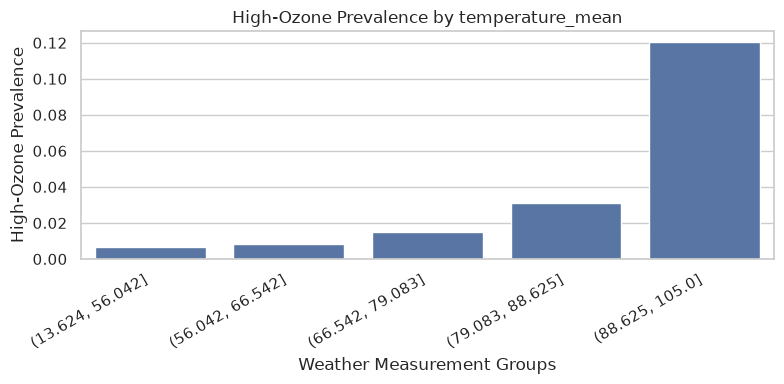

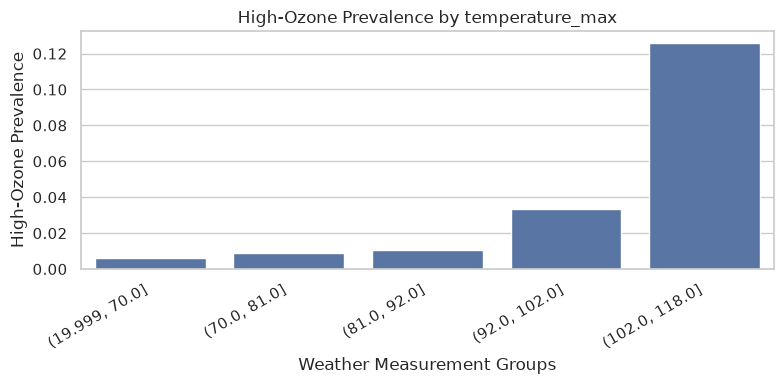

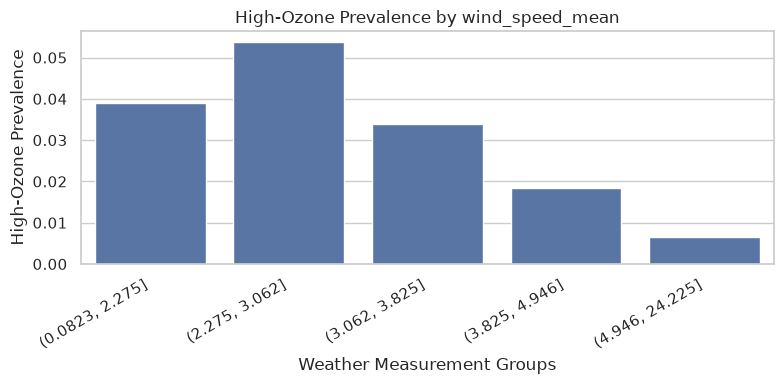

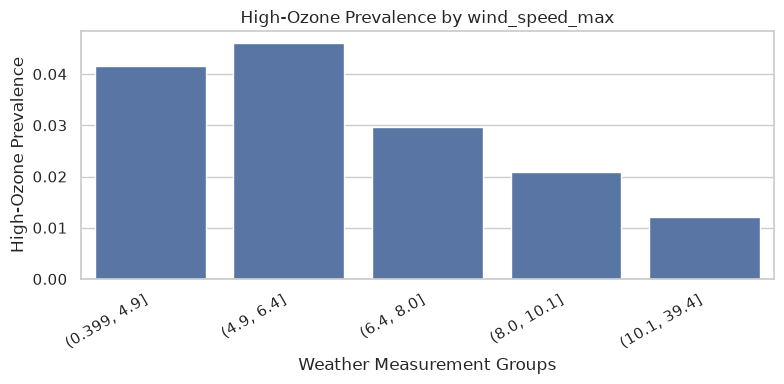

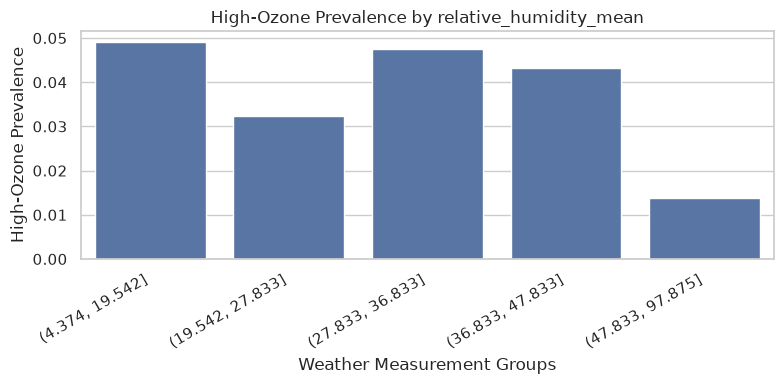

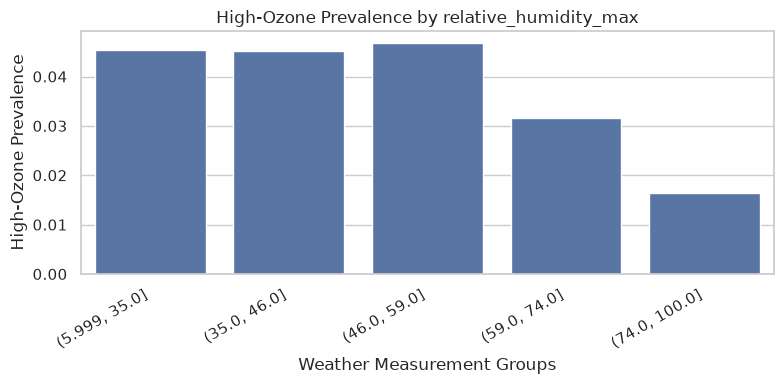

In [24]:
# Examine ozone prevalence across weather conditions

weather_columns = [
    "temperature_mean",
    "temperature_max",
    "wind_speed_mean",
    "wind_speed_max",
    "relative_humidity_mean",
    "relative_humidity_max"
]

for column in weather_columns:

    # Divide weather measurements into five groups
    weather_bins = pd.qcut(
        df[column],
        q=5,
        duplicates="drop"
    )

    # Calculate high-ozone prevalence within each group
    rates = df.groupby(weather_bins, observed=False)["high_ozone"].mean()

    # Plot results
    plt.figure(figsize=(8, 4))

    sns.barplot(
        x=rates.index.astype(str),
        y=rates.values
    )

    plt.title(f"High-Ozone Prevalence by {column}")
    plt.xlabel("Weather Measurement Groups")
    plt.ylabel("High-Ozone Prevalence")

    plt.xticks(rotation=30, ha="right")

    plt.tight_layout()
    plt.show()

## 4. Site and Geographic EDA

In [51]:
# Examine the number of unique sites, regions, and counties
geographic_columns = ["site_code", "region", "county_name"]

for column in geographic_columns:

    print(f"\n{column}")
    print("-" * 40)
    print("Unique values:", df[column].nunique())
    print("Missing values:", df[column].isnull().sum())

    # Display the most frequently occurring values
    display(df[column].value_counts())


site_code
----------------------------------------
Unique values: 46
Missing values: 0


site_code
site_3b4fabeb    1092
site_64f8ec06    1092
site_5d0c13ff    1092
site_6bd704b1    1089
site_91f4702d    1089
site_4acff404    1088
site_7e0cd974    1088
site_3dd32b9e    1088
site_521f8e29    1085
site_e34f11ae    1083
site_71ed4398    1083
site_d0124f15    1082
site_8f5db169    1082
site_04e8b248    1080
site_c9b52637    1079
site_f5fbcf01    1078
site_c3077177    1078
site_87bfc9f2    1078
site_3ef9574f    1077
site_3b02ae70    1076
site_c599e20c    1073
site_c715259d    1072
site_1d0ac6a0    1072
site_d3b8baa8    1072
site_d114202b    1071
site_a99d4802    1070
site_35366dac    1069
site_d5147807    1065
site_b62e9acb    1065
site_df0f0c5c    1063
site_7953fe8e    1063
site_975a9410    1059
site_d5f7e9f2    1057
site_cec4e1d7    1056
site_6efccddf    1053
site_e9ffdbb0    1052
site_635f9b8b    1050
site_b135171c    1039
site_e04fb8dc    1035
site_ccca8970    1034
site_1385df32    1011
site_66e710a6     688
site_ccc2c520     638
site_aebe56de     621
site_5f39aea5     586



region
----------------------------------------
Unique values: 5
Missing values: 0


region
Central     29725
Southern     9568
Northern     4240
Western      2133
Eastern      1071
Name: count, dtype: int64


county_name
----------------------------------------
Unique values: 10
Missing values: 0


county_name
Maricopa    24493
Pima         8503
Pinal        5232
Coconino     2130
Gila         1071
Yuma         1070
Cochise      1065
La Paz       1063
Yavapai      1057
Navajo       1053
Name: count, dtype: int64

,site_code,record_count,high_ozone_prevalence
15,site_66e710a6,688,0.325581
1,site_1385df32,1011,0.074184
27,site_b135171c,1039,0.071222
2,site_1d0ac6a0,1072,0.070896
20,site_7e0cd974,1088,0.069853
11,site_5d0c13ff,1092,0.067766
12,site_5f39aea5,586,0.061433
7,site_3ef9574f,1077,0.059424
41,site_df0f0c5c,1063,0.054563
14,site_64f8ec06,1092,0.054029


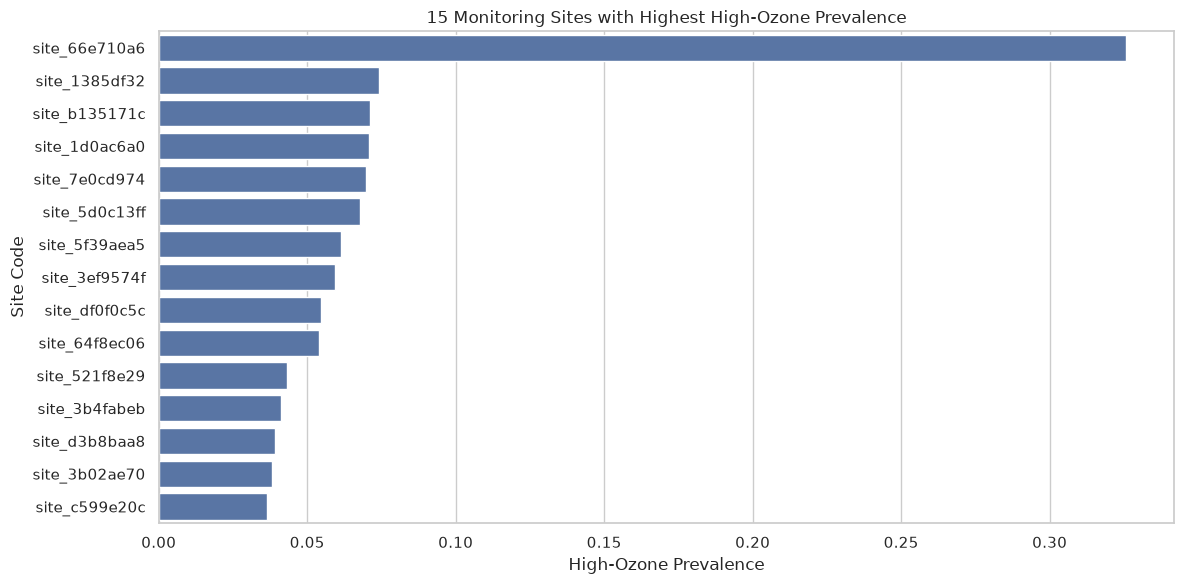

In [47]:
# Calculate record counts and high-ozone prevalence by site
site_ozone = (
    df.groupby("site_code")
    .agg(
        record_count=("high_ozone", "size"),
        high_ozone_prevalence=("high_ozone", "mean")
    )
    .reset_index()
)

# Keep sites with at least 30 records
site_ozone = site_ozone[site_ozone["record_count"] >= 30]

# Sort by high-ozone prevalence
site_ozone = site_ozone.sort_values(
    "high_ozone_prevalence",
    ascending=False
)

# Display the 15 sites with the highest prevalence
display(site_ozone.head(15))

# Plot the results
plt.figure(figsize=(12, 6))

sns.barplot(
    data=site_ozone.head(15),
    x="high_ozone_prevalence",
    y="site_code"
)

plt.title("15 Monitoring Sites with Highest High-Ozone Prevalence")
plt.xlabel("High-Ozone Prevalence")
plt.ylabel("Site Code")

plt.tight_layout()
plt.show()

,county_name,record_count,high_ozone_prevalence
4,Maricopa,24493,0.050014
2,Gila,1071,0.029879
7,Pinal,5232,0.018922
9,Yuma,1070,0.007477
0,Cochise,1065,0.003756
6,Pima,8503,0.003411
3,La Paz,1063,0.001881
5,Navajo,1053,0.000950
1,Coconino,2130,0.000939
8,Yavapai,1057,0.000000


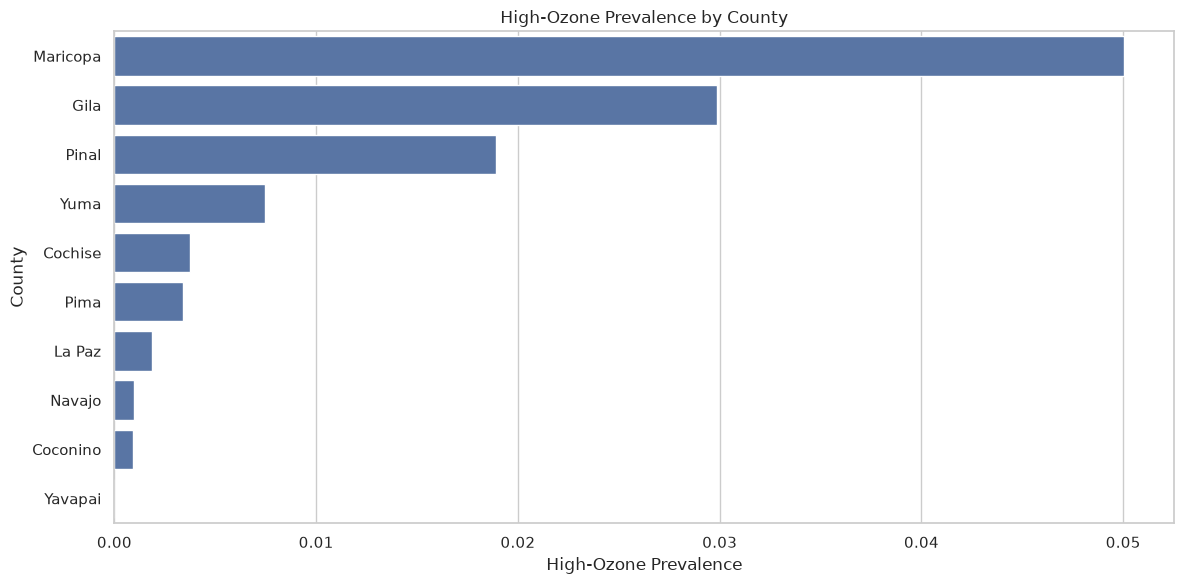

In [52]:
# Calculate record counts and high-ozone prevalence by county
county_ozone = (
    df.groupby("county_name")
    .agg(
        record_count=("high_ozone", "size"),
        high_ozone_prevalence=("high_ozone", "mean")
    )
    .reset_index()
)

# Sort counties by high-ozone prevalence
county_ozone = county_ozone.sort_values(
    "high_ozone_prevalence",
    ascending=False
)

# Display county-level results
display(county_ozone)

# Plot high-ozone prevalence by county
plt.figure(figsize=(12, 6))

sns.barplot(
    data=county_ozone,
    x="high_ozone_prevalence",
    y="county_name"
)

plt.title("High-Ozone Prevalence by County")
plt.xlabel("High-Ozone Prevalence")
plt.ylabel("County")

plt.tight_layout()
plt.show()

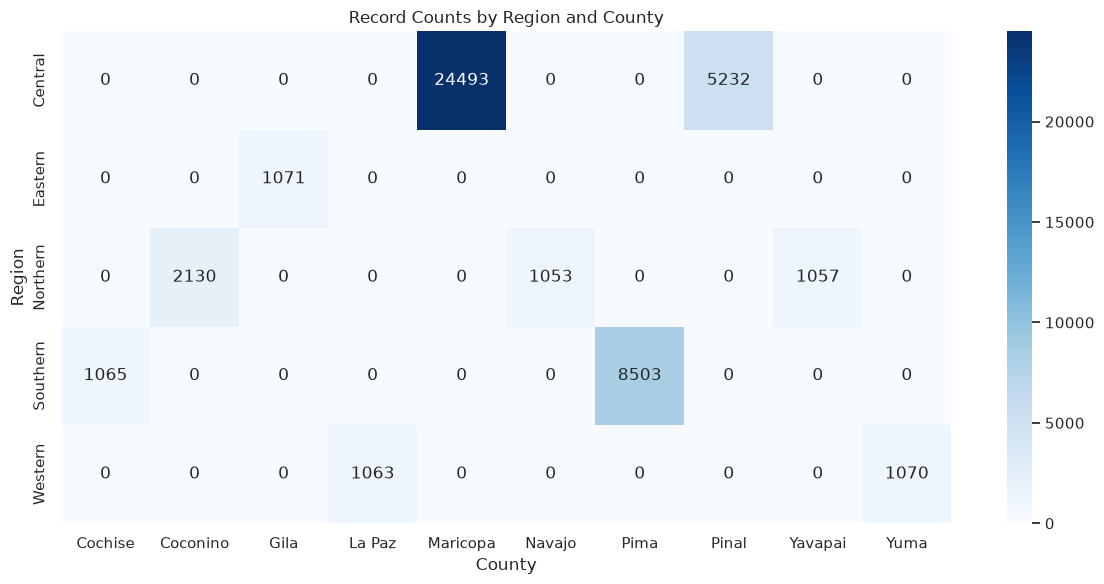

In [54]:
# Count records for each region and county combination
region_county = pd.crosstab(
    df["region"],
    df["county_name"]
)

# Plot the distribution
plt.figure(figsize=(12, 6))

sns.heatmap(
    region_county,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Record Counts by Region and County")
plt.xlabel("County")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

## 5. Correlation Analysis

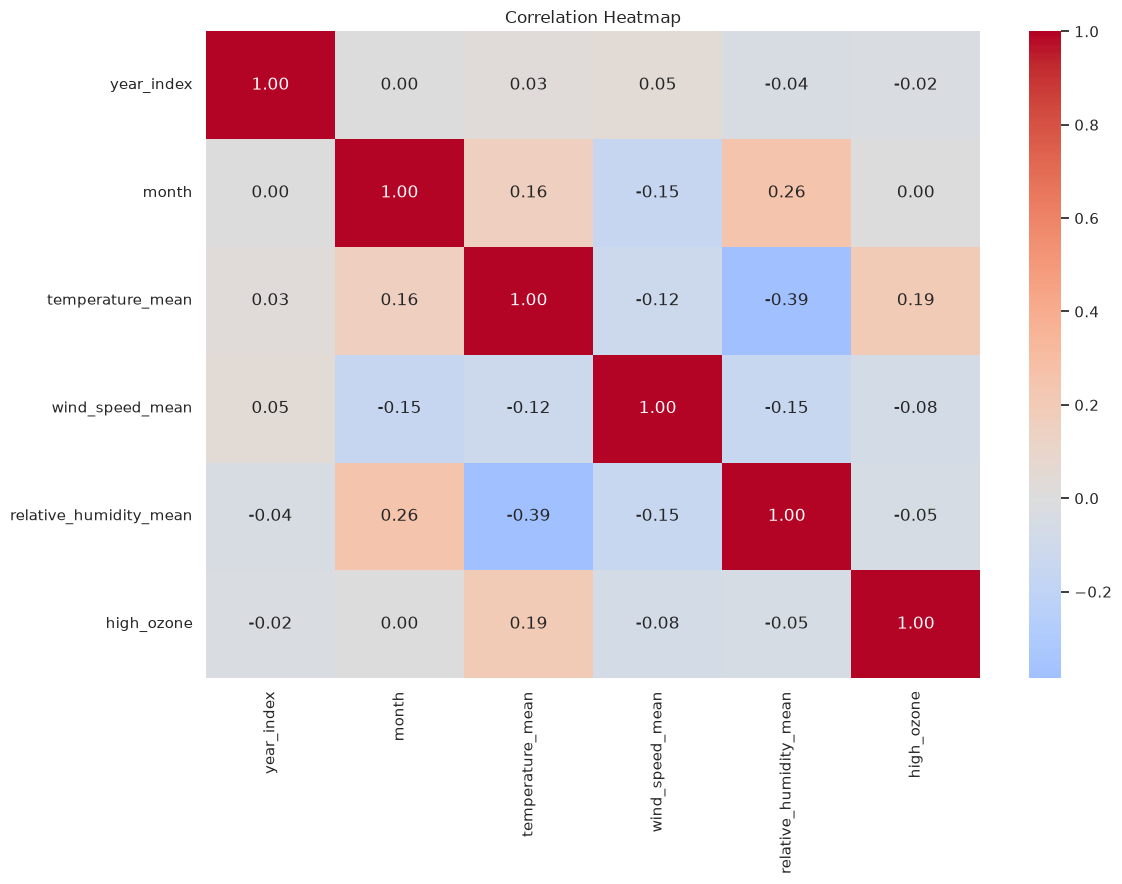

In [26]:
# Select numeric columns, excluding missingness indicators and maximum weather variables
exclude_columns = [
    "temperature_missing",
    "wind_speed_missing",
    "relative_humidity_missing",
    "temperature_max",
    "wind_speed_max",
    "relative_humidity_max"
]

numeric_df = df.select_dtypes(include=np.number).drop(
    columns=exclude_columns,
    errors="ignore"
)

# Calculate correlations
correlations = numeric_df.corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## 6. Trends Over Time

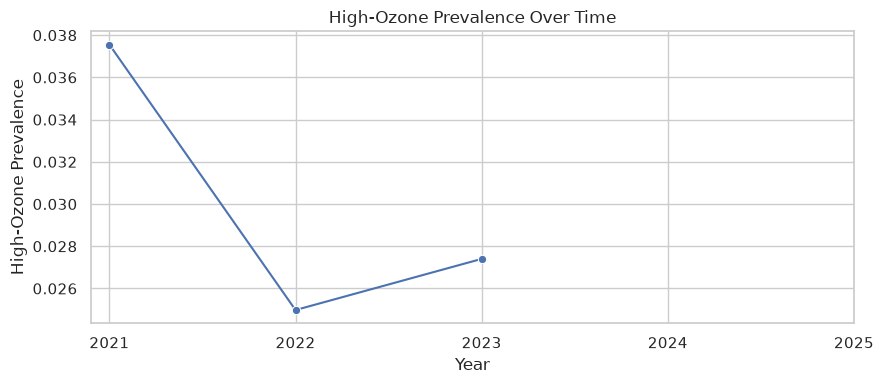

In [31]:
# Calculate high-ozone prevalence by year
yearly_ozone = df.groupby("year_index")["high_ozone"].mean()

# Convert year index to calendar year (2021 = 0, 2025 = 4)
yearly_ozone.index = yearly_ozone.index + 2021

# Plot yearly prevalence
plt.figure(figsize=(9, 4))

sns.lineplot(
    x=yearly_ozone.index,
    y=yearly_ozone.values,
    marker="o"
)

plt.title("High-Ozone Prevalence Over Time")
plt.xlabel("Year")
plt.ylabel("High-Ozone Prevalence")
plt.xticks(range(2021, 2026))

plt.tight_layout()
plt.show()

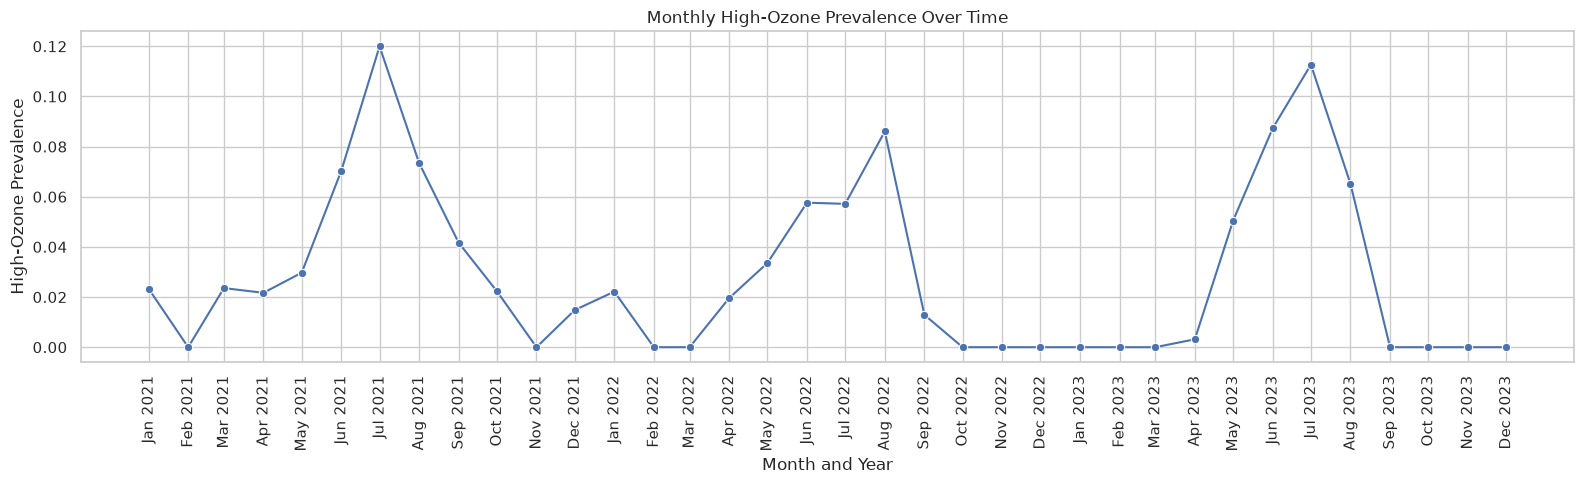

In [34]:
# Calculate monthly high-ozone prevalence by year
monthly_ozone = (
    df.groupby(["year_index", "month"])["high_ozone"]
    .mean()
    .reset_index()
)

# Convert year index to calendar year (2021 = 0)
monthly_ozone["year"] = monthly_ozone["year_index"] + 2021

# Create a date column for plotting
monthly_ozone["date"] = pd.to_datetime(
    monthly_ozone[["year", "month"]].assign(day=1)
)

# Plot monthly prevalence over time
plt.figure(figsize=(16, 5))

sns.lineplot(
    data=monthly_ozone,
    x="date",
    y="high_ozone",
    marker="o"
)

plt.title("Monthly High-Ozone Prevalence Over Time")
plt.xlabel("Month and Year")
plt.ylabel("High-Ozone Prevalence")

# Show a tick for every month
plt.xticks(
    monthly_ozone["date"],
    monthly_ozone["date"].dt.strftime("%b %Y"),
    rotation=90
)

plt.tight_layout()
plt.show()

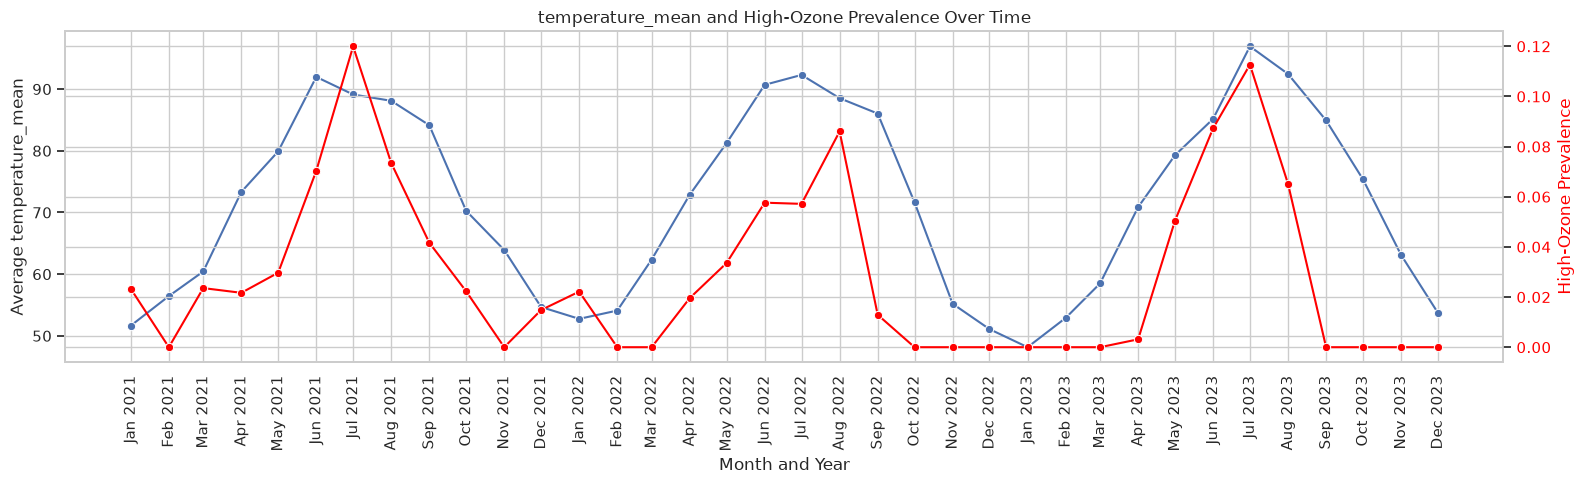

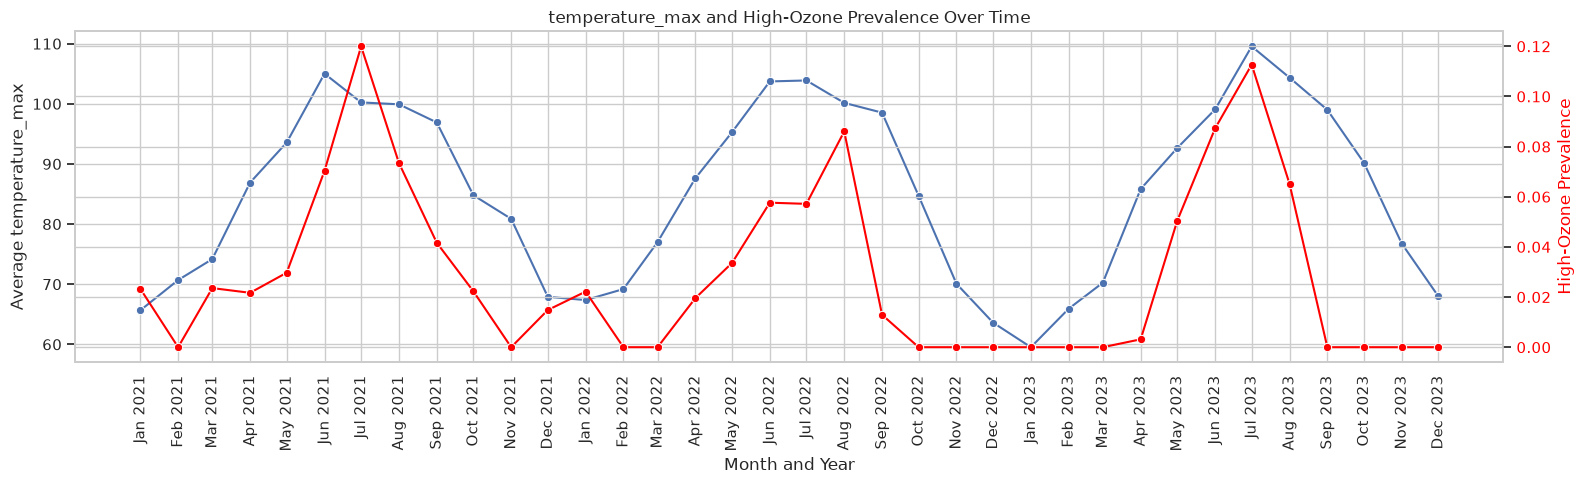

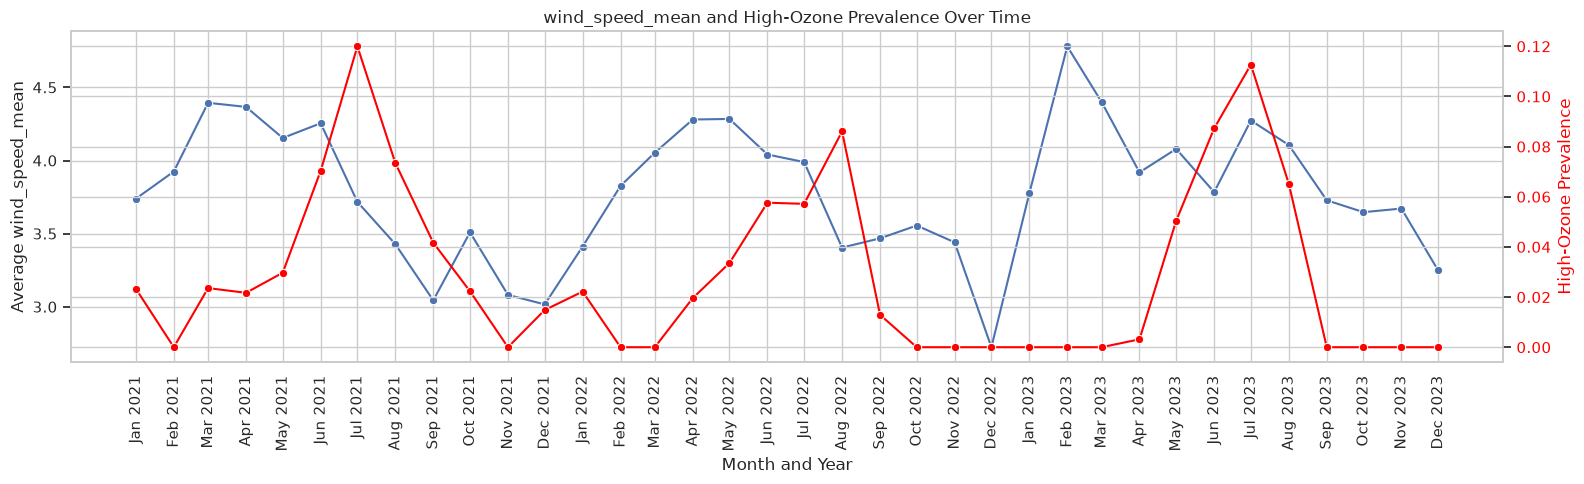

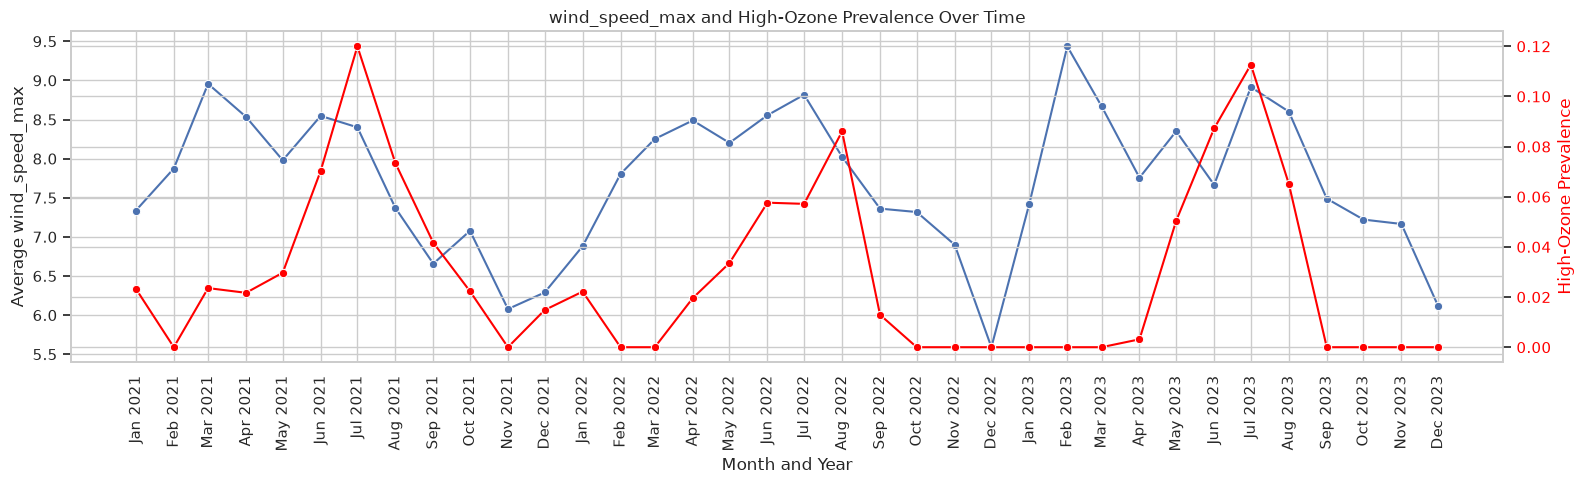

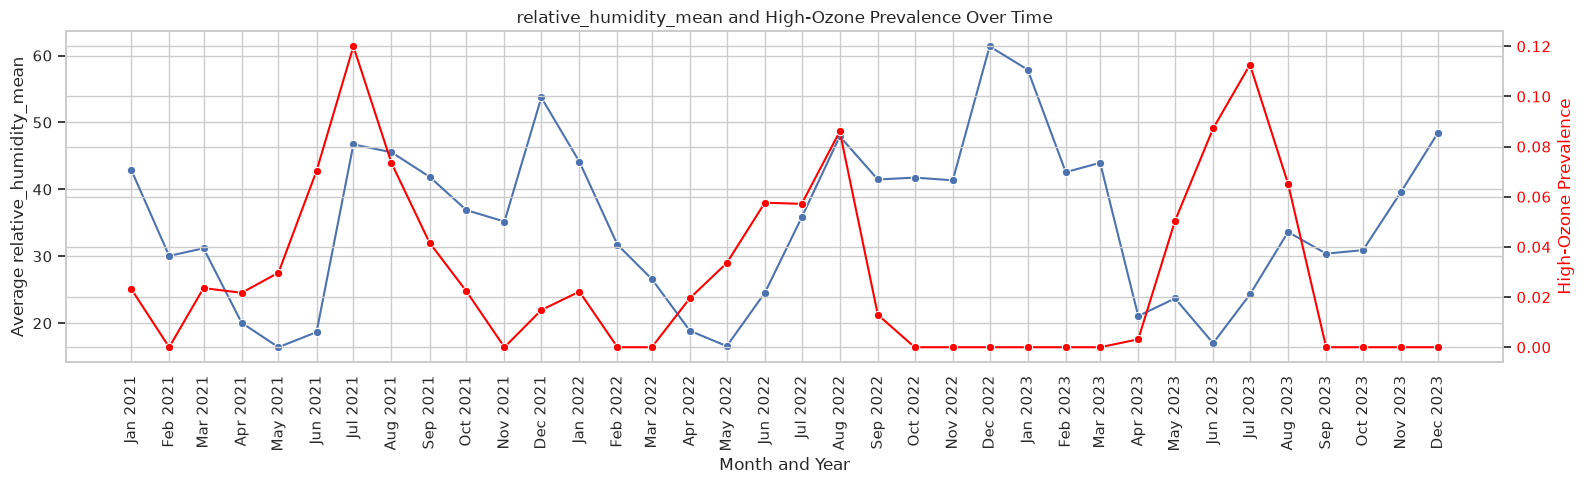

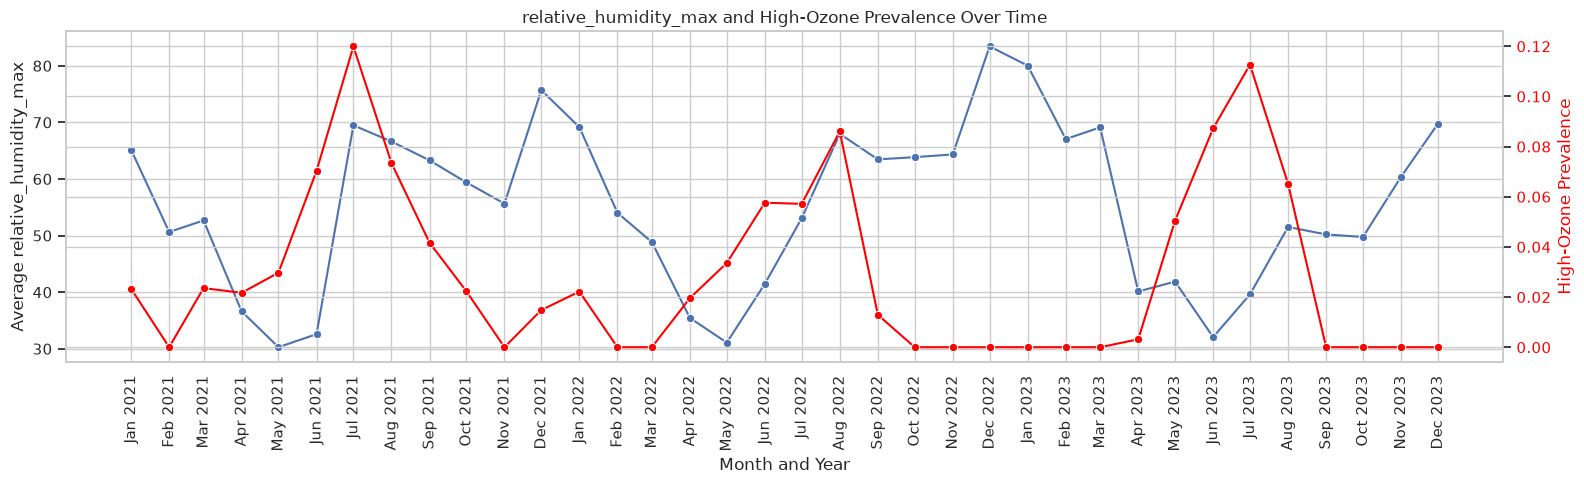

In [36]:
# Calculate monthly high-ozone prevalence
monthly_ozone = (
    df.groupby(["year_index", "month"])["high_ozone"]
    .mean()
    .reset_index()
)

# Convert year index to calendar year
monthly_ozone["year"] = monthly_ozone["year_index"] + 2021

# Create a date column for plotting
monthly_ozone["date"] = pd.to_datetime(
    monthly_ozone[["year", "month"]].assign(day=1)
)

# Plot each weather measurement with high-ozone prevalence
for column in weather_columns:

    # Calculate monthly average weather measurement
    monthly_weather = (
        df.groupby(["year_index", "month"])[column]
        .mean()
        .reset_index()
    )

    # Convert year index to calendar year
    monthly_weather["year"] = monthly_weather["year_index"] + 2021

    # Create a date column
    monthly_weather["date"] = pd.to_datetime(
        monthly_weather[["year", "month"]].assign(day=1)
    )

    # Create the plot
    fig, ax1 = plt.subplots(figsize=(16, 5))

    # Plot average weather measurement
    sns.lineplot(
        data=monthly_weather,
        x="date",
        y=column,
        marker="o",
        ax=ax1
    )

    ax1.set_xlabel("Month and Year")
    ax1.set_ylabel(f"Average {column}")
    ax1.set_title(f"{column} and High-Ozone Prevalence Over Time")

    # Create a second y-axis for high-ozone prevalence
    ax2 = ax1.twinx()

    # Overlay high-ozone prevalence in red
    sns.lineplot(
        data=monthly_ozone,
        x="date",
        y="high_ozone",
        marker="o",
        color="red",
        ax=ax2
    )

    ax2.set_ylabel("High-Ozone Prevalence", color="red")
    ax2.tick_params(axis="y", labelcolor="red")

    # Show a tick for every available month
    ax1.set_xticks(monthly_ozone["date"])
    ax1.set_xticklabels(
        monthly_ozone["date"].dt.strftime("%b %Y"),
        rotation=90
    )

    plt.tight_layout()
    plt.show()

## 7. Probability and Inference

In [38]:
# Calculate probability of high ozone by month
monthly_probability = df.groupby("month")["high_ozone"].agg(
    ["count", "sum", "mean"]
)

monthly_probability.columns = [
    "Total Observations",
    "High Ozone Observations",
    "Probability of High Ozone"
]

display(monthly_probability)

,Total Observations,High Ozone Observations,Probability of High Ozone
month,,,
1,3858,59,0.015293
2,3488,0,0.000000
3,3869,31,0.008012
4,3938,59,0.014982
5,4078,154,0.037764
6,3939,282,0.071592
7,4029,389,0.096550
8,4093,307,0.075006
9,3946,72,0.018246


In [39]:
# Calculate probability of high ozone by season
season_probability = df.groupby("season")["high_ozone"].agg(
    ["count", "sum", "mean"]
)

season_probability.columns = [
    "Total Observations",
    "High Ozone Observations",
    "Probability of High Ozone"
]

display(season_probability)

,Total Observations,High Ozone Observations,Probability of High Ozone
season,,,
fall,11660,102,0.008748
spring,11885,244,0.020530
summer,12061,978,0.081088
winter,11131,78,0.007007


In [40]:
# Calculate probability of high ozone by region
region_probability = df.groupby("region")["high_ozone"].agg(
    ["count", "sum", "mean"]
)

region_probability.columns = [
    "Total Observations",
    "High Ozone Observations",
    "Probability of High Ozone"
]

display(region_probability)

,Total Observations,High Ozone Observations,Probability of High Ozone
region,,,
Central,29725,1324,0.044542
Eastern,1071,32,0.029879
Northern,4240,3,0.000708
Southern,9568,33,0.003449
Western,2133,10,0.004688


region,Central,Eastern,Northern,Southern,Western
season,,,,,
fall,0.013829,0.000000,0.000000,0.000000,0.000000
spring,0.030543,0.025830,0.000000,0.001234,0.005566
summer,0.116306,0.094697,0.002841,0.012680,0.013333
winter,0.011246,0.000000,0.000000,0.000000,0.000000


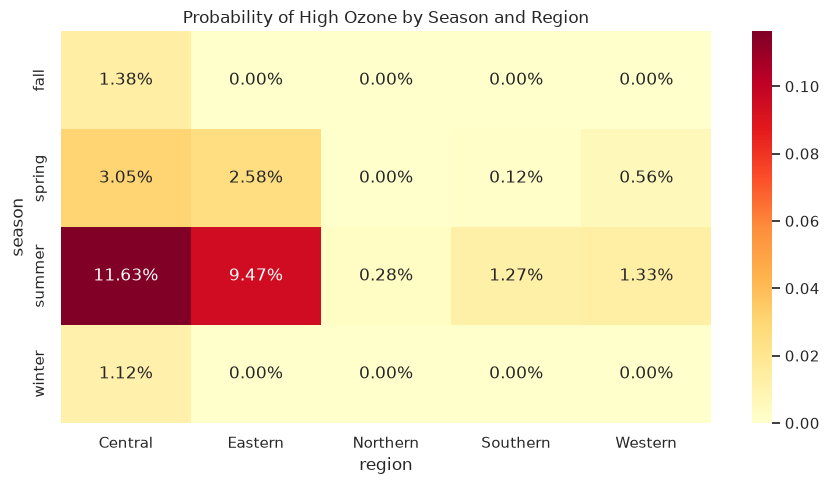

In [41]:
# Examine probability by season and region together
season_region_probability = df.pivot_table(
    values="high_ozone",
    index="season",
    columns="region",
    aggfunc="mean"
)

display(season_region_probability)

# Visualize conditional probabilities
plt.figure(figsize=(9, 5))

sns.heatmap(
    season_region_probability,
    annot=True,
    fmt=".2%",
    cmap="YlOrRd"
)

plt.title("Probability of High Ozone by Season and Region")

plt.tight_layout()
plt.show()

## 8. Modeling Considerations

In [42]:
# Check correlations between numeric weather predictors

weather_numeric = df[weather_columns]

correlation_matrix = weather_numeric.corr()

display(correlation_matrix)

# Identify highly correlated predictor pairs
high_correlations = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i):

        correlation = correlation_matrix.iloc[i, j]

        if abs(correlation) > 0.8:

            high_correlations.append({
                "Variable 1": correlation_matrix.columns[i],
                "Variable 2": correlation_matrix.columns[j],
                "Correlation": correlation
            })

print("Highly correlated predictor pairs:")

display(pd.DataFrame(high_correlations))

,temperature_mean,temperature_max,wind_speed_mean,wind_speed_max,relative_humidity_mean,relative_humidity_max
temperature_mean,1.000000,0.978171,-0.119917,-0.035571,-0.385187,-0.407036
temperature_max,0.978171,1.000000,-0.173426,-0.084105,-0.449802,-0.439667
wind_speed_mean,-0.119917,-0.173426,1.000000,0.878520,-0.151515,-0.179960
wind_speed_max,-0.035571,-0.084105,0.878520,1.000000,-0.119728,-0.134211
relative_humidity_mean,-0.385187,-0.449802,-0.151515,-0.119728,1.000000,0.942718
relative_humidity_max,-0.407036,-0.439667,-0.179960,-0.134211,0.942718,1.000000


Highly correlated predictor pairs:


,Variable 1,Variable 2,Correlation
0,temperature_max,temperature_mean,0.978171
1,wind_speed_max,wind_speed_mean,0.878520
2,relative_humidity_max,relative_humidity_mean,0.942718


In [43]:
# VIF provides another way to examine multicollinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numeric weather predictors
vif_data = df[weather_columns].dropna()

# Remove constant columns
vif_data = vif_data.loc[:, vif_data.nunique() > 1]

# Calculate VIF
vif_results = pd.DataFrame()

vif_results["Variable"] = vif_data.columns

vif_results["VIF"] = [
    variance_inflation_factor(vif_data.values, i)
    for i in range(vif_data.shape[1])
]

display(vif_results.sort_values("VIF", ascending=False))

,Variable,VIF
1,temperature_max,34.907052
0,temperature_mean,32.421497
4,relative_humidity_mean,12.188094
5,relative_humidity_max,11.054761
2,wind_speed_mean,4.690708
3,wind_speed_max,4.331730
